## Paso 1 de 3: preparar el entorno
Ejecuta las tres celdas siguientes en orden. Solo la tercera te pide un archivo: `datos_ini.csv` (el dataset es privado y no se descarga de GitHub).

In [1]:
#1/3 Instalamos MLflow y creamos las carpetas
!pip install -q mlflow
!mkdir -p fuentes datos

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 62.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [2]:
%%writefile fuentes/datos_prep.py
import re
import pandas as pd
from sklearn.model_selection import train_test_split


def cargar_datos(ruta="datos/datos_ini.csv"):
    # utf-8-sig quita el caracter invisible del inicio del archivo
    return pd.read_csv(ruta, encoding="utf-8-sig")


def limpiar_texto(texto):
    texto = str(texto).lower()
    # Reemplaza los CURP por una palabra generica
    texto = re.sub(r"\b[a-z]{4}\d{6}[hm][a-z]{5}[a-z0-9]\d\b", " curp ", texto)
    # Deja solo letras y espacios
    texto = re.sub(r"[^a-zñ ]", " ", texto)
    # Quita espacios repetidos
    return re.sub(r"\s+", " ", texto).strip()


def limpiar_datos(df, ruta="datos/datos_limp.csv"):
    df = df.dropna(subset=["texto", "categoria"])
    df["texto"] = df["texto"].apply(limpiar_texto)
    # Quita textos vacios y repetidos
    df = df[df["texto"] != ""]
    df = df.drop_duplicates(subset="texto")
    df.to_csv(ruta, index=False)
    return df


def dividir_datos(df):
    # 80% entrenamiento, 20% prueba. La columna "archivo" no se usa
    # porque su nombre revela la clase.
    return train_test_split(df["texto"], df["categoria"], test_size=0.2,
                            random_state=42, stratify=df["categoria"])

Writing fuentes/datos_prep.py


In [3]:
#3/3 Subimos SOLO el dataset (datos_ini.csv)
import glob, shutil
from google.colab import files

files.upload()
for f in glob.glob("*.csv"):
    shutil.move(f, "datos/datos_ini.csv")

!ls -la fuentes datos

Saving datos_ini.csv to datos_ini.csv
datos:
total 9576
drwxr-xr-x 2 root root    4096 Oct 17 03:09 .
drwxr-xr-x 1 root root    4096 Oct 17 03:09 ..
-rw-r--r-- 1 root root 9796788 Oct 17 03:09 datos_ini.csv

fuentes:
total 12
drwxr-xr-x 2 root root 4096 Oct 17 03:08 .
drwxr-xr-x 1 root root 4096 Oct 17 03:09 ..
-rw-r--r-- 1 root root 1186 Oct 17 03:08 datos_prep.py


## Paso 2 de 3: entrenamiento y evaluación

In [4]:
import sys
sys.path.append("fuentes")

import hashlib
import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

from datos_prep import cargar_datos, limpiar_datos, dividir_datos

In [5]:
#Cargamos los datos originales
df = cargar_datos()
print(df.shape)
df[["categoria", "archivo"]].head()

(4173, 3)


,categoria,archivo
0,Actas de nacimiento,10000_ACT NAC.pdf
1,Actas de nacimiento,10001_ACTA DE NAC.pdf
2,Actas de nacimiento,1000_ACTA DE NAC.pdf
3,Actas de nacimiento,10008_ACT NAC.pdf
4,Actas de nacimiento,10011_ACT NAC.pdf


In [6]:
#Se revisa la calidad de los datos
print(df.isnull().sum())
print(df.duplicated(subset="texto").sum(), "textos repetidos")
print(df["categoria"].value_counts())
print(df["texto"].str.split().str.len().describe())

texto        0
categoria    0
archivo      0
dtype: int64
6 textos repetidos
categoria
CURP                       700
Certificados Secundaria    700
Equivalencia               700
Certificado Parcial        698
Certificado Final          694
Actas de nacimiento        681
Name: count, dtype: int64
count    4173.000000
mean      286.820513
std        77.264126
min        53.000000
25%       248.000000
50%       288.000000
75%       309.000000
max       664.000000
Name: texto, dtype: float64


In [7]:
#limpiamos y guardamos
df_limpio = limpiar_datos(df)
print("Antes:", df.shape, "Después:", df_limpio.shape)
df_limpio[["categoria", "archivo"]].head()

Antes: (4173, 3) Después: (4167, 3)


,categoria,archivo
0,Actas de nacimiento,10000_ACT NAC.pdf
1,Actas de nacimiento,10001_ACTA DE NAC.pdf
2,Actas de nacimiento,1000_ACTA DE NAC.pdf
3,Actas de nacimiento,10008_ACT NAC.pdf
4,Actas de nacimiento,10011_ACT NAC.pdf


In [8]:
#Se divide el entrenamiento y prueba
X_train, X_test, y_train, y_test = dividir_datos(df_limpio)
print(X_train.shape, X_test.shape)

(3333,) (834,)


In [9]:
#Identificamos la version de los datos
with open("datos/datos_limp.csv", "rb") as f:
    hash_datos = hashlib.md5(f.read()).hexdigest()
print(hash_datos)

1c994a3b886ebee2941c302baefea806


In [10]:
#Se definen los dos algoritmos
modelos = {
    "regresion_logistica": (
        Pipeline([("tfidf", TfidfVectorizer(max_features=5000)),
                  ("modelo", LogisticRegression(max_iter=1000))]),
        {"modelo__C": [1, 10, 100]},
    ),
    "random_forest": (
        Pipeline([("tfidf", TfidfVectorizer(max_features=5000)),
                  ("modelo", RandomForestClassifier(random_state=42))]),
        {"modelo__n_estimators": [100, 200], "modelo__max_depth": [20, None]},
    ),
}

In [11]:
#Entrenamos, validamos y registramos en MLflow
mlflow.set_experiment("actividad5_clasificador")
mejores = {}

for nombre, (modelo, parametros) in modelos.items():
    with mlflow.start_run(run_name=nombre):
        busqueda = GridSearchCV(modelo, parametros, cv=5, scoring="f1_weighted")
        busqueda.fit(X_train, y_train)

        mejor = busqueda.best_estimator_
        pred = mejor.predict(X_test)
        prob = mejor.predict_proba(X_test)
        mejores[nombre] = mejor

        mlflow.log_param("algoritmo", nombre)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("hash_datos", hash_datos)
        mlflow.log_params(busqueda.best_params_)

        mlflow.log_metric("cv_f1", busqueda.best_score_)
        mlflow.log_metric("accuracy", accuracy_score(y_test, pred))
        mlflow.log_metric("precision", precision_score(y_test, pred, average="weighted"))
        mlflow.log_metric("recall", recall_score(y_test, pred, average="weighted"))
        mlflow.log_metric("f1", f1_score(y_test, pred, average="weighted"))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, prob, multi_class="ovr",
                                                   labels=mejor.classes_))

        pd.DataFrame(busqueda.cv_results_).to_csv("cv_results.csv", index=False)
        mlflow.log_artifact("cv_results.csv")
        mlflow.log_artifact("datos/datos_limp.csv")
        mlflow.sklearn.log_model(mejor, "modelo", serialization_format="cloudpickle")

        print(nombre, busqueda.best_params_, round(busqueda.best_score_, 3))

2026/10/17 03:09:49 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/17 03:09:49 INFO mlflow.store.db.utils: Updating database tables
2026/10/17 03:09:53 INFO mlflow.tracking.fluent: Experiment with name 'actividad5_clasificador' does not exist. Creating a new experiment.
2026/10/17 03:10:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 03:10:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


regresion_logistica {'modelo__C': 100} 0.986


2026/10/17 03:11:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/17 03:11:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


random_forest {'modelo__max_depth': 20, 'modelo__n_estimators': 200} 0.987


In [12]:
#Tabla comparativa
resultados = mlflow.search_runs(experiment_names=["actividad5_clasificador"])
columnas = ["tags.mlflow.runName", "metrics.cv_f1", "metrics.accuracy",
            "metrics.precision", "metrics.recall", "metrics.f1", "metrics.roc_auc"]
resultados[columnas]

,tags.mlflow.runName,metrics.cv_f1,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1,metrics.roc_auc
0,random_forest,0.986787,0.989209,0.989319,0.989209,0.989216,0.999102
1,regresion_logistica,0.986192,0.983213,0.983283,0.983213,0.983190,0.998304


In [13]:
#Reporte por clase
for nombre, modelo in mejores.items():
    print("=====", nombre)
    print(classification_report(y_test, modelo.predict(X_test)))

===== regresion_logistica
                         precision    recall  f1-score   support

    Actas de nacimiento       1.00      0.99      1.00       136
                   CURP       1.00      1.00      1.00       140
      Certificado Final       0.99      0.96      0.97       139
    Certificado Parcial       0.96      0.95      0.95       139
Certificados Secundaria       0.99      1.00      1.00       140
           Equivalencia       0.97      0.99      0.98       140

               accuracy                           0.98       834
              macro avg       0.98      0.98      0.98       834
           weighted avg       0.98      0.98      0.98       834

===== random_forest
                         precision    recall  f1-score   support

    Actas de nacimiento       0.99      0.99      0.99       136
                   CURP       1.00      1.00      1.00       140
      Certificado Final       1.00      0.97      0.99       139
    Certificado Parcial       0.96      

In [14]:
#Validamos parametros, metricas y artefactos en MLflow
cliente = mlflow.MlflowClient()
experimento = cliente.get_experiment_by_name("actividad5_clasificador")
corridas = cliente.search_runs([experimento.experiment_id])

for c in corridas:
    print("=====", c.data.tags["mlflow.runName"])
    print("Parámetros:", c.data.params)
    print("Métricas:", c.data.metrics)
    print("Artefactos:", [a.path for a in cliente.list_artifacts(c.info.run_id)])

===== random_forest
Parámetros: {'algoritmo': 'random_forest', 'cv_folds': '5', 'hash_datos': '1c994a3b886ebee2941c302baefea806', 'modelo__max_depth': '20', 'modelo__n_estimators': '200'}
Métricas: {'cv_f1': 0.986786718892224, 'accuracy': 0.9892086330935251, 'precision': 0.9893191829515111, 'recall': 0.9892086330935251, 'f1': 0.9892164170095946, 'roc_auc': 0.999102298915445}
Artefactos: ['cv_results.csv', 'datos_limp.csv']
===== regresion_logistica
Parámetros: {'algoritmo': 'regresion_logistica', 'cv_folds': '5', 'hash_datos': '1c994a3b886ebee2941c302baefea806', 'modelo__C': '100'}
Métricas: {'cv_f1': 0.9861922884818751, 'accuracy': 0.9832134292565947, 'precision': 0.9832834354670769, 'recall': 0.9832134292565947, 'f1': 0.9831900963308804, 'roc_auc': 0.9983036627528711}
Artefactos: ['cv_results.csv', 'datos_limp.csv']


In [15]:
# tipo de datos y estadisticas
print(df_limpio.dtypes)
print(df_limpio["texto"].str.split().str.len().describe())

texto        object
categoria    object
archivo      object
dtype: object
count    4167.000000
mean      304.841133
std        94.519916
min        53.000000
25%       249.000000
50%       300.000000
75%       336.000000
max       848.000000
Name: texto, dtype: float64


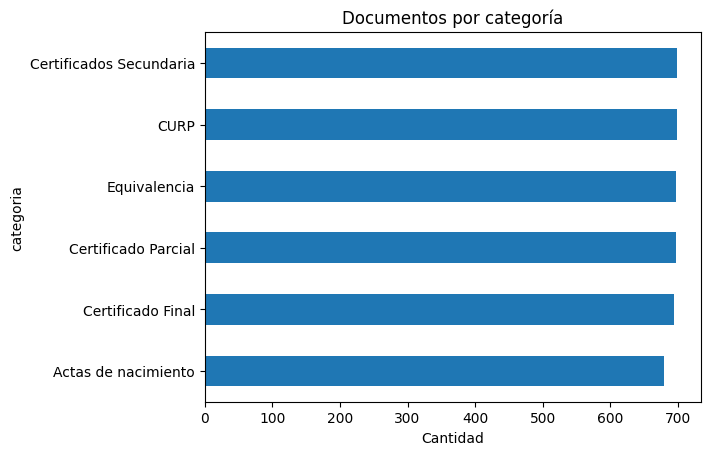

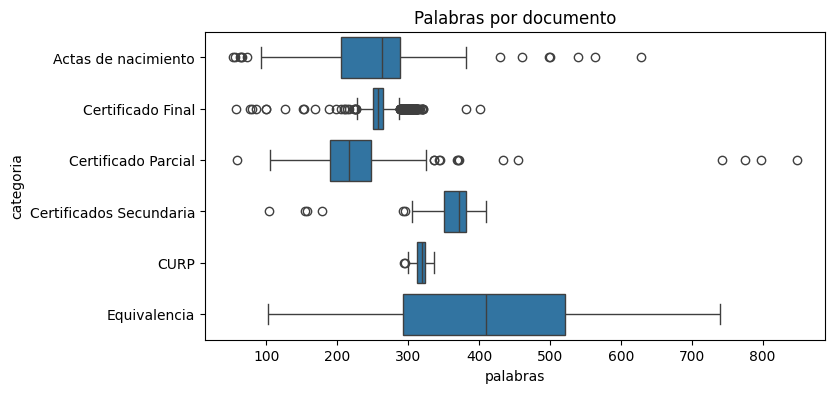

Actas de nacimiento -> del, civil, nacimiento, nacionalidad, apellido, registro, chihuahua, edad
CURP -> personales, identidad, datos, los, gobernacion, registro, acceso, para
Certificado Final -> del, semestre, mod, estado, matematicas, formacion, chihuahua, mexico
Certificado Parcial -> del, estado, chihuahua, con, estudios, gobierno, semestre, bien
Certificados Secundaria -> por, del, firma, electronica, autoridad, educativa, avanzada, educacion
Equivalencia -> del, certificado, estudios, plantel, matematicas, parcial, chihuahua, telebachillerato


In [16]:
#visualizamos los datos
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfica 1: distribución de clases
df_limpio["categoria"].value_counts().sort_values().plot(kind="barh")
plt.title("Documentos por categoría")
plt.xlabel("Cantidad")
plt.show()

# Gráfica 2: longitud del texto por clase
df_limpio["palabras"] = df_limpio["texto"].str.split().str.len()
plt.figure(figsize=(8, 4))
sns.boxplot(x="palabras", y="categoria", data=df_limpio)
plt.title("Palabras por documento")
plt.show()

# Palabras más características de cada clase
tfidf = TfidfVectorizer(max_features=3000)
M = tfidf.fit_transform(df_limpio["texto"])
palabras = np.array(tfidf.get_feature_names_out())
for cat in sorted(df_limpio["categoria"].unique()):
    filas = (df_limpio["categoria"] == cat).values
    medias = np.asarray(M[filas].mean(axis=0)).ravel()
    print(cat, "->", ", ".join(palabras[medias.argsort()[::-1][:8]]))

regresion_logistica ROC-AUC: 0.9983


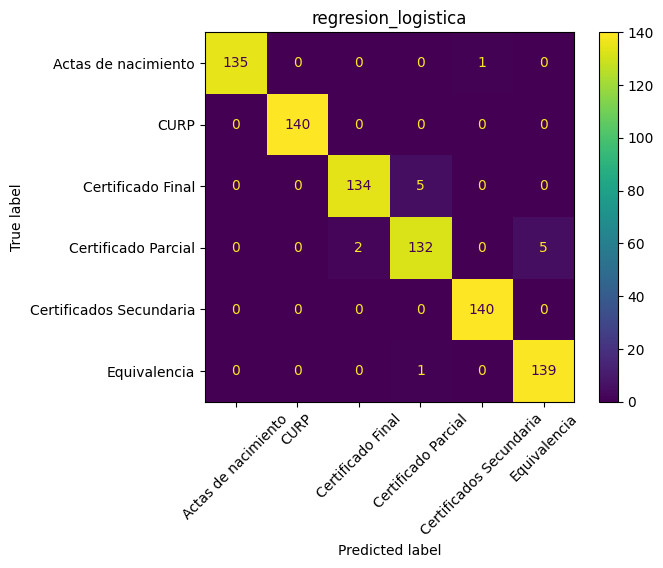

random_forest ROC-AUC: 0.9991


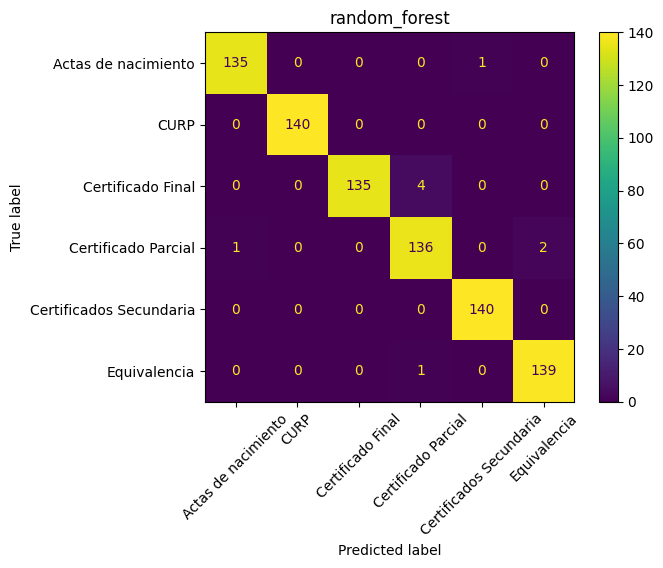

In [17]:
#ROC-AUC y matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay

for nombre, modelo in mejores.items():
    prob = modelo.predict_proba(X_test)
    auc = roc_auc_score(y_test, prob, multi_class="ovr", labels=modelo.classes_)
    print(nombre, "ROC-AUC:", round(auc, 4))
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, xticks_rotation=45)
    plt.title(nombre)
    plt.show()

In [18]:
##Comparación estadística
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from scipy import stats

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
lr = cross_val_score(mejores["regresion_logistica"], X_train, y_train, cv=cv, scoring="f1_weighted", n_jobs=-1)
rf = cross_val_score(mejores["random_forest"], X_train, y_train, cv=cv, scoring="f1_weighted", n_jobs=-1)

print("Regresión logística:", round(lr.mean(), 4), "+/-", round(lr.std(), 4))
print("Random forest:", round(rf.mean(), 4), "+/-", round(rf.std(), 4))
print("t pareada:", stats.ttest_rel(lr, rf))
print("Wilcoxon:", stats.wilcoxon(lr, rf))

Regresión logística: 0.9865 +/- 0.0045
Random forest: 0.9858 +/- 0.0041
t pareada: TtestResult(statistic=np.float64(1.0770414416466692), pvalue=np.float64(0.2996714685742125), df=np.int64(14))
Wilcoxon: WilcoxonResult(statistic=np.float64(40.0), pvalue=np.float64(0.27685546875))
